# 01 — Data Understanding and Quality Assessment

## Project: Credit Risk Analytics

### 1.1 Project Overview

This notebook begins the data understanding and quality assessment stage of the Credit Risk Analytics project.

The objective is to investigate the structure, characteristics, and quality of the credit card default dataset before performing exploratory data analysis or developing machine learning models.

### 1.2 Problem Statement

Credit card default creates financial risk for lending institutions. This project investigates historical credit card client data to identify patterns associated with payment default and evaluate the potential of machine learning for predicting default risk.

### 1.3 Dataset Information

- **Dataset:** Default of Credit Card Clients
- **Source:** UCI Machine Learning Repository
- **Observations:** To be verified
- **Features:** To be verified
- **Target variable:** `default.payment.next.month`

### 1.4 Objectives

1. Load the original dataset without modifying it.
2. Examine its dimensions and structure.
3. Identify column names and data types.
4. Assess missing values and duplicate records.
5. Examine the target variable distribution.
6. Document data quality issues requiring further investigation.

### 1.5 Important Note

All observations and conclusions will be based on the actual dataset outputs. No cleaning, feature engineering, or model training will be performed during the initial inspection.


In [1]:
# Data Understanding
import numpy as np
import pandas as pd

### 1.6 Loading the Dataset

In this step, we will load the original credit card default dataset into a Pandas DataFrame.

The dataset is stored locally in the project's `data/` directory. We will preserve the original file and perform all subsequent analysis in memory or on separate derived files.

After loading the dataset, we will inspect a small sample of records to verify that the file has been read correctly.

In [ ]:
# Data Loading
from pathlib import Path

DATA_PATH = Path("../data/default of credit card clients.xls")

df = pd.read_excel(DATA_PATH)

df.head()

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0


### 1.7 Initial Dataset Inspection

The dataset was successfully loaded into a Pandas DataFrame.

The initial inspection reveals that the dataset contains 25 columns. However, the displayed column names include generic labels such as `X1`, `X2`, and `X3`.

The first row appears to contain the actual variable names, including `ID`, `LIMIT_BAL`, `SEX`, `AGE`, and `default payment next month`.

This indicates that the dataset requires further structural investigation before analysis.

The original dataset will remain unchanged during this inspection stage.

In [3]:
# Display the number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the overall dimensions
print("Dataset shape:", df.shape)

Number of rows: 30001
Number of columns: 25
Dataset shape: (30001, 25)


### 1.8 Dataset Dimensions

The initial dataset contains 30,001 rows and 25 columns.

The dataset is expected to contain 30,000 customer records and 24 actual variables. The additional row represents the column headers stored as the first data record.

This structural issue will be investigated and corrected during the data preparation stage.

In [4]:
# Display all column names
print("Column Names:\n")

for column in df.columns:
    print(column)

Column Names:

Unnamed: 0
X1
X2
X3
X4
X5
X6
X7
X8
X9
X10
X11
X12
X13
X14
X15
X16
X17
X18
X19
X20
X21
X22
X23
Y


In [5]:
# Display the first row containing the actual column names
df.iloc[0]

Unnamed: 0                            ID
X1                             LIMIT_BAL
X2                                   SEX
X3                             EDUCATION
X4                              MARRIAGE
X5                                   AGE
X6                                 PAY_0
X7                                 PAY_2
X8                                 PAY_3
X9                                 PAY_4
X10                                PAY_5
X11                                PAY_6
X12                            BILL_AMT1
X13                            BILL_AMT2
X14                            BILL_AMT3
X15                            BILL_AMT4
X16                            BILL_AMT5
X17                            BILL_AMT6
X18                             PAY_AMT1
X19                             PAY_AMT2
X20                             PAY_AMT3
X21                             PAY_AMT4
X22                             PAY_AMT5
X23                             PAY_AMT6
Y             de

### 1.9 Identifying the Actual Column Headers

Inspection of the first row reveals that the dataset contains its actual column names as the first data record.

The original headers are stored under generic column labels such as `X1`, `X2`, and `Y`.

The first column, currently named `Unnamed: 0`, contains the `ID` variable.

We will preserve this observation and correct the column structure during the data preparation stage.

In [6]:
# Display DataFrame information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30001 entries, 0 to 30000
Data columns (total 25 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  30001 non-null  object
 1   X1          30001 non-null  object
 2   X2          30001 non-null  object
 3   X3          30001 non-null  object
 4   X4          30001 non-null  object
 5   X5          30001 non-null  object
 6   X6          30001 non-null  object
 7   X7          30001 non-null  object
 8   X8          30001 non-null  object
 9   X9          30001 non-null  object
 10  X10         30001 non-null  object
 11  X11         30001 non-null  object
 12  X12         30001 non-null  object
 13  X13         30001 non-null  object
 14  X14         30001 non-null  object
 15  X15         30001 non-null  object
 16  X16         30001 non-null  object
 17  X17         30001 non-null  object
 18  X18         30001 non-null  object
 19  X19         30001 non-null  object
 20  X20         30001

### 1.10 Dataset Structure and Data Types

The DataFrame information summary reveals the following:

- Total records: 30,001
- Total columns: 25
- All columns currently have the `object` data type.
- Every column contains 30,001 non-null values.
- Approximate memory usage is 5.7 MB.

The object data types are likely related to the incorrect header interpretation identified earlier.

The dataset requires structural correction and data type validation before further analysis.

In [7]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing Values in Each Column:\n")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:

Unnamed: 0    0
X1            0
X2            0
X3            0
X4            0
X5            0
X6            0
X7            0
X8            0
X9            0
X10           0
X11           0
X12           0
X13           0
X14           0
X15           0
X16           0
X17           0
X18           0
X19           0
X20           0
X21           0
X22           0
X23           0
Y             0
dtype: int64

Total Missing Values: 0


### 1.11 Missing Value Assessment

The missing-value assessment shows that all 25 columns contain zero detected null values.

The dataset has no missing values according to Pandas' `isnull()` check.

Therefore, missing-value imputation is not currently required. Other data-quality issues, including duplicate records, incorrect data types, and invalid categorical values, will be investigated separately.

In [8]:
# Count duplicate records
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


### 1.12 Duplicate Record Assessment

The duplicate record assessment identified zero duplicate rows in the dataset.

No exact duplicate records were detected using Pandas' `duplicated()` method.

Therefore, no duplicate-row removal is currently required. Further validation will be performed during data preparation.

In [9]:
# Display the first five records
df.head()

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0


### 1.13 Initial Dataset Inspection Summary

The initial inspection identified the following characteristics:

- The dataset contains 30,001 rows and 25 columns.
- The first row contains the actual column names.
- The remaining 30,000 rows represent customer records.
- All columns are currently interpreted as object data types.
- No missing values were detected.
- No exact duplicate records were identified.
- The dataset contains an additional unnamed column representing the customer ID.

### Identified Issues

1. Incorrect column headers.
2. An extra header row included in the dataset.
3. Incorrectly inferred data types.

These issues will be addressed during the data preparation stage.

### Next Steps

- Correct the column names.
- Remove the additional header row.
- Validate data types.
- Investigate categorical values and numerical distributions.


In [10]:
# Display unique values in the SEX column
print("Unique values:", df["X2"].unique())

# Count occurrences of each value
print("\nValue Counts:")
print(df["X2"].value_counts())

Unique values: ['SEX' 2 1]

Value Counts:
X2
2      18112
1      11888
SEX        1
Name: count, dtype: int64


### 1.14 Categorical Variable Inspection — SEX

The SEX column contains three unique values:

- 1: Male
- 2: Female
- SEX: An incorrect header value present in the first data row.

The value counts show 11,888 records coded as 1 and 18,112 records coded as 2.

The additional SEX entry confirms that the original column headers were incorrectly interpreted as data.

This issue will be resolved during structural correction.

In [13]:
# Display unique values in the EDUCATION column
print("Unique values:", df["X3"].unique())

# Count occurrences of each value
print("\nValue Counts:")
print(df["X3"].value_counts())

Unique values: ['EDUCATION' 2 1 3 5 4 6 0]

Value Counts:
X3
2            14030
1            10585
3             4917
5              280
4              123
6               51
0               14
EDUCATION        1
Name: count, dtype: int64


### 1.15 Categorical Variable Inspection — EDUCATION

The EDUCATION column contains the following distinct values:

0, 1, 2, 3, 4, 5, 6, and an additional string value 'EDUCATION'.

The string value represents the original column header incorrectly stored as a data record.

The numerical values represent encoded education categories. Codes 0, 4, 5, and 6 require further investigation to determine their appropriate treatment.

The sorting operation also revealed that the column currently contains mixed data types.

In [14]:
# Display unique values in the MARRIAGE column
print("Unique values:", df["X4"].unique())

# Count occurrences of each value
print("\nValue Counts:")
print(df["X4"].value_counts())

Unique values: ['MARRIAGE' 1 2 3 0]

Value Counts:
X4
2           15964
1           13659
3             323
0              54
MARRIAGE        1
Name: count, dtype: int64


### 1.16 Categorical Variable Inspection — EDUCATION and MARRIAGE

#### EDUCATION

The EDUCATION variable contains seven numerical category codes: 0, 1, 2, 3, 4, 5, and 6.

Codes 0, 4, 5, and 6 represent less common or other education categories and require further investigation.

#### MARRIAGE

The MARRIAGE variable contains four numerical category codes: 0, 1, 2, and 3.

The value 0 represents an unknown or other category, while 1, 2, and 3 represent different marital-status categories.

#### Data Quality Observations

Both variables contain an additional string value corresponding to their original column headers.

These header values will be removed during structural correction. Unusual numerical category codes will be investigated separately during preprocessing.

In [16]:
# Display the frequency distribution of ages
print("Age Distribution:\n")
print(df["X5"].value_counts().sort_index(key=lambda x: x.astype(str)))

# Display the number of unique age values
print("\nNumber of Unique Ages:", df["X5"].nunique())

Age Distribution:

X5
21       67
22      560
23      931
24     1127
25     1186
26     1256
27     1477
28     1409
29     1605
30     1395
31     1217
32     1158
33     1146
34     1162
35     1113
36     1108
37     1041
38      944
39      954
40      870
41      824
42      794
43      670
44      700
45      617
46      570
47      501
48      466
49      452
50      411
51      340
52      304
53      325
54      247
55      209
56      178
57      122
58      122
59       83
60       67
61       56
62       44
63       31
64       31
65       24
66       25
67       16
68        5
69       15
70       10
71        3
72        3
73        4
74        1
75        3
79        1
AGE       1
Name: count, dtype: int64

Number of Unique Ages: 57


### 1.17 Numerical Variable Inspection — AGE

The AGE column contains 57 unique values, including an additional string value representing the original column header.

The most frequently occurring age is 29, with 1,605 records.

The column requires structural correction before calculating numerical descriptive statistics such as mean, median, minimum, and maximum.

In [17]:
# Display unique repayment status values
print("Unique Values:", df["X6"].unique())

# Count occurrences of each repayment status
print("\nValue Counts:")
print(df["X6"].value_counts())

Unique Values: ['PAY_0' 2 -1 0 -2 1 3 4 8 7 5 6]

Value Counts:
X6
0        14737
-1        5686
1         3688
-2        2759
2         2667
3          322
4           76
5           26
8           19
6           11
7            9
PAY_0        1
Name: count, dtype: int64


### 1.18 Repayment Status Inspection — PAY_0

The PAY_0 variable contains 12 unique values, including an additional string value representing the original column header.

The numerical repayment-status codes range from -2 to 8.

The most frequent category is 0, with 14,737 records, followed by -1, with 5,686 records.

Positive values represent different levels of payment delay, while non-positive values represent other repayment-status categories.

These variables will be investigated further because repayment history is relevant to credit default prediction.

In [22]:
# Identify repayment status columns
repayment_columns = ["X6", "X7", "X8", "X9", "X10", "X11"]

# Exclude the first row containing column names
repayment_data = df.iloc[1:][repayment_columns].copy()

# Convert repayment status values to numeric
repayment_data = repayment_data.apply(pd.to_numeric)

# Calculate frequency distribution
repayment_summary = pd.DataFrame({
    column: repayment_data[column].value_counts()
    for column in repayment_columns
}).fillna(0).astype(int)

# Sort repayment status codes
repayment_summary = repayment_summary.sort_index()

print(repayment_summary.to_string())

       X6     X7     X8     X9    X10    X11
-2   2759   3782   4085   4348   4546   4895
-1   5686   6050   5938   5687   5539   5740
 0  14737  15730  15764  16455  16947  16286
 1   3688     28      4      2      0      0
 2   2667   3927   3819   3159   2626   2766
 3    322    326    240    180    178    184
 4     76     99     76     69     84     49
 5     26     25     21     35     17     13
 6     11     12     23      5      4     19
 7      9     20     27     58     58     46
 8     19      1      3      2      1      2


### 1.19 Repayment Status Analysis

The six repayment-status variables (PAY_0, PAY_2, PAY_3, PAY_4, PAY_5, and PAY_6) were examined to understand clients' repayment behaviour.

Key observations:

- Code 0 is the most frequent category across all six repayment-status variables.
- Codes -1 and -2 also occur frequently.
- Positive repayment-status codes represent payment delays, with higher values indicating longer delays.
- The frequency of positive repayment-status codes varies across the six observation periods.

Repayment history is expected to be an important predictor in the credit default classification task. These variables will be examined further during exploratory data analysis and model development.

In [23]:
# Identify billing amount columns
billing_columns = ["X12", "X13", "X14", "X15", "X16", "X17"]

# Exclude the original header row and convert values to numeric
billing_data = df.iloc[1:][billing_columns].apply(pd.to_numeric)

# Generate descriptive statistics
billing_summary = billing_data.describe().T

print(billing_summary)

       count          mean           std       min      25%      50%  \
X12  30000.0  51223.330900  73635.860576 -165580.0  3558.75  22381.5   
X13  30000.0  49179.075167  71173.768783  -69777.0  2984.75  21200.0   
X14  30000.0  47013.154800  69349.387427 -157264.0  2666.25  20088.5   
X15  30000.0  43262.948967  64332.856134 -170000.0  2326.75  19052.0   
X16  30000.0  40311.400967  60797.155770  -81334.0  1763.00  18104.5   
X17  30000.0  38871.760400  59554.107537 -339603.0  1256.00  17071.0   

          75%        max  
X12  67091.00   964511.0  
X13  64006.25   983931.0  
X14  60164.75  1664089.0  
X15  54506.00   891586.0  
X16  50190.50   927171.0  
X17  49198.25   961664.0  


### 1.20 Billing Amount Analysis

The six billing amount variables (BILL_AMT1 to BILL_AMT6) were examined using descriptive statistics.

Key observations:

- The average billing amount decreases across the six observation periods.
- Mean values are considerably higher than median values, suggesting positively skewed distributions.
- Billing amounts show substantial variation across clients.
- Negative billing amounts are present in all six variables.
- Some observations contain unusually large billing amounts.

Negative values and extreme observations will be investigated during data cleaning and exploratory data analysis rather than being removed automatically.

In [24]:
# Identify payment amount columns
payment_columns = ["X18", "X19", "X20", "X21", "X22", "X23"]

# Exclude the original header row and convert values to numeric
payment_data = df.iloc[1:][payment_columns].apply(pd.to_numeric)

# Generate descriptive statistics
payment_summary = payment_data.describe().T

print(payment_summary)

       count         mean           std  min      25%     50%      75%  \
X18  30000.0  5663.580500  16563.280354  0.0  1000.00  2100.0  5006.00   
X19  30000.0  5921.163500  23040.870402  0.0   833.00  2009.0  5000.00   
X20  30000.0  5225.681500  17606.961470  0.0   390.00  1800.0  4505.00   
X21  30000.0  4826.076867  15666.159744  0.0   296.00  1500.0  4013.25   
X22  30000.0  4799.387633  15278.305679  0.0   252.50  1500.0  4031.50   
X23  30000.0  5215.502567  17777.465775  0.0   117.75  1500.0  4000.00   

           max  
X18   873552.0  
X19  1684259.0  
X20   896040.0  
X21   621000.0  
X22   426529.0  
X23   528666.0  


### 1.21 Payment Amount Analysis

The six payment amount variables (PAY_AMT1 to PAY_AMT6) were examined using descriptive statistics.

Key observations:

- Mean payment amounts are considerably higher than median values, suggesting positively skewed distributions.
- All six variables contain zero payment values.
- Payment amounts show substantial variation across clients.
- Some observations contain exceptionally large payment amounts.
- Average payment amounts fluctuate across the six observation periods.

Zero and unusually large payment values will be retained for further investigation rather than removed automatically.

In [25]:
# Exclude the original header row
target_data = df.iloc[1:]["Y"]

# Convert target values to numeric
target_data = pd.to_numeric(target_data)

# Display class frequencies
print("Target Variable Distribution:")
print(target_data.value_counts().sort_index())

# Calculate class percentages
print("\nTarget Class Percentages:")
print((target_data.value_counts(normalize=True).sort_index() * 100).round(2))

# Display unique target values
print("\nUnique Target Values:", sorted(target_data.unique()))

Target Variable Distribution:
Y
0    23364
1     6636
Name: count, dtype: int64

Target Class Percentages:
Y
0    77.88
1    22.12
Name: proportion, dtype: float64

Unique Target Values: [np.int64(0), np.int64(1)]


### 1.22 Target Variable Analysis

The target variable, default payment next month, represents whether a client defaults on their credit card payment in the following month.

The dataset contains two classes:

- 0: No default — 23,364 records (77.88%).
- 1: Default — 6,636 records (22.12%).

Key observations:

- The dataset contains approximately 3.52 times more non-default records than default records.
- The target variable is imbalanced, with default cases representing 22.12% of the dataset.
- Accuracy alone may not provide a reliable evaluation of classification models.

Therefore, precision, recall, F1-score, confusion matrix and ROC-AUC will also be considered during model evaluation.

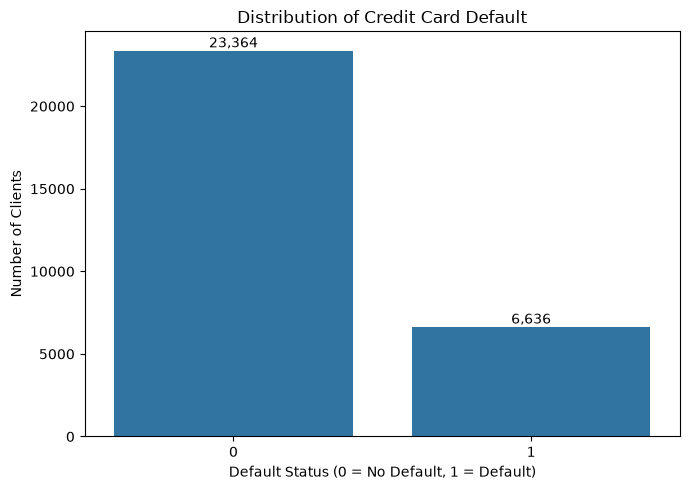

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate target class frequencies
target_counts = target_data.value_counts().sort_index()

# Create a bar chart
plt.figure(figsize=(7, 5))
sns.barplot(
    x=target_counts.index.astype(str),
    y=target_counts.values
)

plt.title("Distribution of Credit Card Default")
plt.xlabel("Default Status (0 = No Default, 1 = Default)")
plt.ylabel("Number of Clients")

# Display count labels
for index, value in enumerate(target_counts.values):
    plt.text(index, value + 200, f"{value:,}", ha="center")

plt.tight_layout()
plt.show()

## 1.23 Initial Data Understanding Summary

The initial inspection of the UCI Default of Credit Card Clients dataset revealed the following:

1. **Dataset dimensions:** 30,000 observations and 24 actual variables, including the identifier and target.
2. **Column headers:** The original variable names were stored in the first row rather than being assigned as column headers during import.
3. **Data types:** All columns were initially loaded as object type because of the header-row issue.
4. **Missing values:** No missing values were detected during the initial inspection.
5. **Duplicate records:** No exact duplicate rows were identified.
6. **Categorical variables:** Variables such as SEX, EDUCATION and MARRIAGE contain encoded categories, including some unusual values requiring further investigation.
7. **Repayment history:** Six repayment-status variables contain both positive and non-positive codes.
8. **Billing amounts:** Billing variables contain negative values and substantial variation.
9. **Payment amounts:** Payment variables contain zero values and highly variable payment amounts.
10. **Target variable:** The dataset contains 23,364 non-default records and 6,636 default records, indicating class imbalance.

### Identified Data Preparation Requirements

- Correct the column headers.
- Remove the original header row from the observations.
- Convert appropriate columns into numeric data types.
- Investigate unusual categorical values.
- Examine negative billing amounts and extreme observations.
- Reassess missing values and duplicate records after structural correction.
- Separate identifier, predictor and target variables appropriately.

These findings establish the foundation for the subsequent data cleaning and exploratory data analysis stages.

## 1.24 Dataset Structure Correction

During the initial inspection, we identified that the first row of the imported dataset contains the actual column names.

The dataset will now be restructured by:

- Assigning the first row as the DataFrame column names.
- Removing that row from the actual observations.
- Resetting the DataFrame index.
- Preserving the original imported dataset separately for reference.

This correction will allow us to perform accurate data type conversion, validation and subsequent analysis.

In [27]:
# Preserve the original imported dataset
df_raw = df.copy()

# Extract actual column names from the first row
new_columns = df.iloc[0].astype(str).str.strip()

# Create the corrected dataset
df = df.iloc[1:].copy()

# Assign the correct column names
df.columns = new_columns

# Reset the DataFrame index
df.reset_index(drop=True, inplace=True)

# Display the corrected dataset
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [28]:
# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset Information:")
df.info()

Dataset Shape: (30000, 25)

Column Names:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   ID                          30000 non-null  object
 1   LIMIT_BAL                   30000 non-null  object
 2   SEX                         30000 non-null  object
 3   EDUCATION                   30000 non-null  object
 4   MARRIAGE                    30000 non-null  object
 5   AGE                         30000 non-null  object
 6   PAY_0                       30000 non-null  object
 7   PAY_2                       30000 no

### 1.25 Data Type Conversion

After correcting the dataset structure, all 25 columns are still stored using the object data type.

Since the dataset contains numerical values, the columns will be converted into appropriate numeric data types.

This conversion will enable:
- Accurate statistical calculations.
- Numerical operations and comparisons.
- Data visualization.
- Machine learning preprocessing.

Categorical variables will remain numerically represented for now. Their categorical meaning will be handled during subsequent preprocessing.

In [29]:
# Convert all dataset columns into numeric data types
df = df.apply(pd.to_numeric)

# Display updated data types
print("Updated Data Types:")
print(df.dtypes)

# Verify dataset information
print("\nUpdated Dataset Information:")
df.info()

Updated Data Types:
0
ID                            int64
LIMIT_BAL                     int64
SEX                           int64
EDUCATION                     int64
MARRIAGE                      int64
AGE                           int64
PAY_0                         int64
PAY_2                         int64
PAY_3                         int64
PAY_4                         int64
PAY_5                         int64
PAY_6                         int64
BILL_AMT1                     int64
BILL_AMT2                     int64
BILL_AMT3                     int64
BILL_AMT4                     int64
BILL_AMT5                     int64
BILL_AMT6                     int64
PAY_AMT1                      int64
PAY_AMT2                      int64
PAY_AMT3                      int64
PAY_AMT4                      int64
PAY_AMT5                      int64
PAY_AMT6                      int64
default payment next month    int64
dtype: object

Updated Dataset Information:
<class 'pandas.DataFrame'>
RangeIn

### 1.26 Data Type Conversion Results

All 25 columns were successfully converted from object to int64.

Validation results:
- Dataset dimensions: 30,000 rows × 25 columns.
- All columns contain 30,000 non-null observations.
- No conversion errors occurred.
- The original dataset remains preserved in `df_raw`.

The dataset is now structurally consistent and ready for further data-quality validation.

Note: Numerically encoded categorical variables will require appropriate treatment during machine learning preprocessing.

In [31]:
# Check missing values in the corrected dataset
print("Total Missing Values:", df.isna().sum().sum())

# Check duplicate records
print("Duplicate Rows:", df.duplicated().sum())

# Check duplicate client identifiers
print("Duplicate Client IDs:", df["ID"].duplicated().sum())

# Verify identifier range and uniqueness
print("Minimum ID:", df["ID"].min())
print("Maximum ID:", df["ID"].max())
print("Unique IDs:", df["ID"].nunique())

# Verify dataset dimensions
print("Dataset Shape:", df.shape)

Total Missing Values: 0
Duplicate Rows: 0
Duplicate Client IDs: 0
Minimum ID: 1
Maximum ID: 30000
Unique IDs: 30000
Dataset Shape: (30000, 25)


### 1.27 Data Quality Validation

The corrected dataset was subjected to additional data-quality checks.

Validation results:

- Total missing values: 0
- Duplicate rows: 0
- Duplicate client IDs: 0
- Minimum client ID: 1
- Maximum client ID: 30,000
- Unique client IDs: 30,000
- Dataset dimensions: 30,000 rows × 25 columns

All 30,000 client identifiers are unique and sequential.

No missing values or duplicate records were detected. The dataset has passed the initial structural and data-quality validation.

In [32]:
# Inspect categorical variable distributions
categorical_columns = ["SEX", "EDUCATION", "MARRIAGE"]

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts().sort_index().to_string())


SEX
SEX
1    11888
2    18112

EDUCATION
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51

MARRIAGE
MARRIAGE
0       54
1    13659
2    15964
3      323


### 1.28 Categorical Variable Findings

The categorical variables SEX, EDUCATION and MARRIAGE were examined after correcting the dataset structure.

Key findings:

1. SEX contains two categories:
   - 1: Male
   - 2: Female

2. EDUCATION contains seven numerical categories:
   - 1: Graduate school
   - 2: University
   - 3: High school
   - 4: Others
   - 5 and 6: Unknown categories
   - 0: Undocumented category

3. MARRIAGE contains four numerical categories:
   - 1: Married
   - 2: Single
   - 3: Others
   - 0: Undocumented category

The values 0 in EDUCATION and MARRIAGE, along with categories 5 and 6 in EDUCATION, require further investigation.

These categories will be preserved during initial analysis and handled appropriately during data preprocessing.

In [33]:
# Display target variable frequencies
print("Target Variable Distribution:")
print(df["default payment next month"].value_counts().sort_index())

# Calculate target percentages
print("\nTarget Class Percentages:")
print(
    (df["default payment next month"]
     .value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Target Variable Distribution:
default payment next month
0    23364
1     6636
Name: count, dtype: int64

Target Class Percentages:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


### 1.29 Target Variable Validation

The target variable distribution was rechecked after correcting the dataset structure and converting all columns into numeric data types.

The results are consistent with the initial inspection:

- Class 0 (No Default): 23,364 records (77.88%).
- Class 1 (Default): 6,636 records (22.12%).

The target variable contains two distinct classes, confirming that this is a binary classification problem.

The dataset exhibits class imbalance, which will be considered when selecting evaluation metrics and developing classification models.

In [34]:
# Generate descriptive statistics for all numerical columns
numerical_summary = df.describe().T

# Display selected statistical measures
print(
    numerical_summary[
        ["mean", "std", "min", "25%", "50%", "75%", "max"]
    ].to_string()
)

                                     mean            std       min       25%       50%        75%        max
0                                                                                                           
ID                           15000.500000    8660.398374       1.0   7500.75   15000.5   22500.25    30000.0
LIMIT_BAL                   167484.322667  129747.661567   10000.0  50000.00  140000.0  240000.00  1000000.0
SEX                              1.603733       0.489129       1.0      1.00       2.0       2.00        2.0
EDUCATION                        1.853133       0.790349       0.0      1.00       2.0       2.00        6.0
MARRIAGE                         1.551867       0.521970       0.0      1.00       2.0       2.00        3.0
AGE                             35.485500       9.217904      21.0     28.00      34.0      41.00       79.0
PAY_0                           -0.016700       1.123802      -2.0     -1.00       0.0       0.00        8.0
PAY_2              

### 1.31 Numerical Variable Findings

Descriptive statistics were generated for all numerical variables.

Key observations:

- Client ages range from 21 to 79 years.
- Credit limits range from 10,000 to 1,000,000.
- Billing amounts contain negative values and substantial variation.
- Payment amounts contain zero values and unusually large maximum values.
- Mean billing and payment amounts are considerably higher than their respective medians, suggesting positively skewed distributions.
- The target variable has a mean of 0.2212, corresponding to a default rate of 22.12%.

These observations indicate that several numerical variables may contain skewed distributions and extreme observations.

Negative billing values and unusually large amounts will be investigated during exploratory data analysis. They will not be removed without establishing a valid reason.

In [35]:
# Identify billing and payment amount columns
amount_columns = [
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]

# Calculate potential outliers using the IQR method
outlier_summary = []

for column in amount_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Variable": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": outlier_count
    })

# Display results
outlier_df = pd.DataFrame(outlier_summary)

print(outlier_df.to_string(index=False))

 Variable  Lower Bound  Upper Bound  Potential Outliers
BILL_AMT1   -91739.625   162389.375                2400
BILL_AMT2   -88547.500   155538.500                2395
BILL_AMT3   -83581.500   146412.500                2469
BILL_AMT4   -75942.125   132774.875                2622
BILL_AMT5   -70878.250   122831.750                2725
BILL_AMT6   -70657.375   121111.625                2693
 PAY_AMT1    -5009.000    11015.000                2745
 PAY_AMT2    -5417.500    11250.500                2714
 PAY_AMT3    -5782.500    10677.500                2598
 PAY_AMT4    -5279.875     9589.125                2994
 PAY_AMT5    -5416.000     9700.000                2945
 PAY_AMT6    -5705.625     9823.375                2958


### 1.33 Outlier Analysis Findings

The Interquartile Range (IQR) method was applied to all six billing amount and six payment amount variables.

Key observations:

- Potential outliers account for approximately 8% to 10% of observations in these variables.
- BILL_AMT5 contains the highest number of potential outliers among billing variables, with 2,725 records.
- PAY_AMT4 contains the highest number overall, with 2,994 records.
- The payment amount variables have negative lower IQR bounds, so zero payment values are not classified as outliers by this method.
- Extreme observations may represent genuine financial behaviour rather than incorrect data.

No observations will be removed solely because they fall outside the IQR boundaries. Their treatment will be evaluated during subsequent exploratory data analysis and model preprocessing.

In [36]:
# Identify billing amount columns
billing_columns = [
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"
]

# Count negative billing amounts
negative_billing = (df[billing_columns] < 0).sum()

# Calculate percentages
negative_billing_percentage = (
    negative_billing / len(df) * 100
).round(2)

# Combine results
negative_billing_summary = pd.DataFrame({
    "Negative Values": negative_billing,
    "Percentage": negative_billing_percentage
})

print(negative_billing_summary.to_string())

           Negative Values  Percentage
0                                     
BILL_AMT1              590        1.97
BILL_AMT2              669        2.23
BILL_AMT3              655        2.18
BILL_AMT4              675        2.25
BILL_AMT5              655        2.18
BILL_AMT6              688        2.29
